[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB09_brain_activity_data.ipynb)

# Day 2 · Chapter 5 · Notebook 09 — The data our models will be fitted to

> **What we do.** Open the three data sets used in the rest of Chapter 5: the human **connectome** (the input of the
> models), the group **FC** (the target), and the **BOLD signals** of 10 people (to see how FC changes in time).
> The concepts (SC, FC, resting-state networks, dynamic FC) are in the slides; here we look at the numbers.

In [1]:
# @title Setup: load the connectome, the group FC and the BOLD signals
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # the connectome of NB10-NB14
ts = np.load("../data/empirical/fmri_ds000228_schaefer100.npz")["ts"]   # (people, time points, regions), z-scored BOLD
TR = 2.0                                                                 # one volume every 2 s
net = np.array([l.split("_")[2] for l in labels])                        # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])           # regions sorted by network, for display
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]                 # 1 = identical pattern

def show_matrix(ax, M, title, labels_on=True, **kw):
    # region x region matrix, regions grouped by resting-state network
    im = ax.imshow(M[np.ix_(order, order)], **kw); ax.set_title(title)
    sizes = [np.sum(net == n) for n in NETS]; mids = np.cumsum([0] + sizes)
    for e in mids[1:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    ax.set_xticks([]); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS if labels_on else [], fontsize=7)
    return im
print(f"connectome and FC: {len(sc)} cortical regions; BOLD: {ts.shape[0]} people x {ts.shape[1]} volumes "
      f"({ts.shape[1] * TR / 60:.1f} min)")

connectome and FC: 100 cortical regions; BOLD: 10 people x 168 volumes (5.6 min)


## 1. The input and the target: connectome and FC

> **Gist.** Both matrices are averages over the participants of the Human Connectome Project, in the same 100 regions.
> The **connectome** (SC, diffusion MRI) is what we give the model; the **FC** (correlation of resting BOLD) is what the
> model must reproduce.

<details><summary>Data details</summary>

ENIGMA Toolbox (Larivière et al. 2021), Schaefer-100 atlas, regions sorted by the 7 networks of Yeo et al. (2011).
SC: fibre counts, scaled so that a region receives a total weight of at most 1, plus a weight of 0.5 between mirror
regions of the two hemispheres (tractography misses many of these fibres). FC: Fisher-z correlations, group average.
</details>

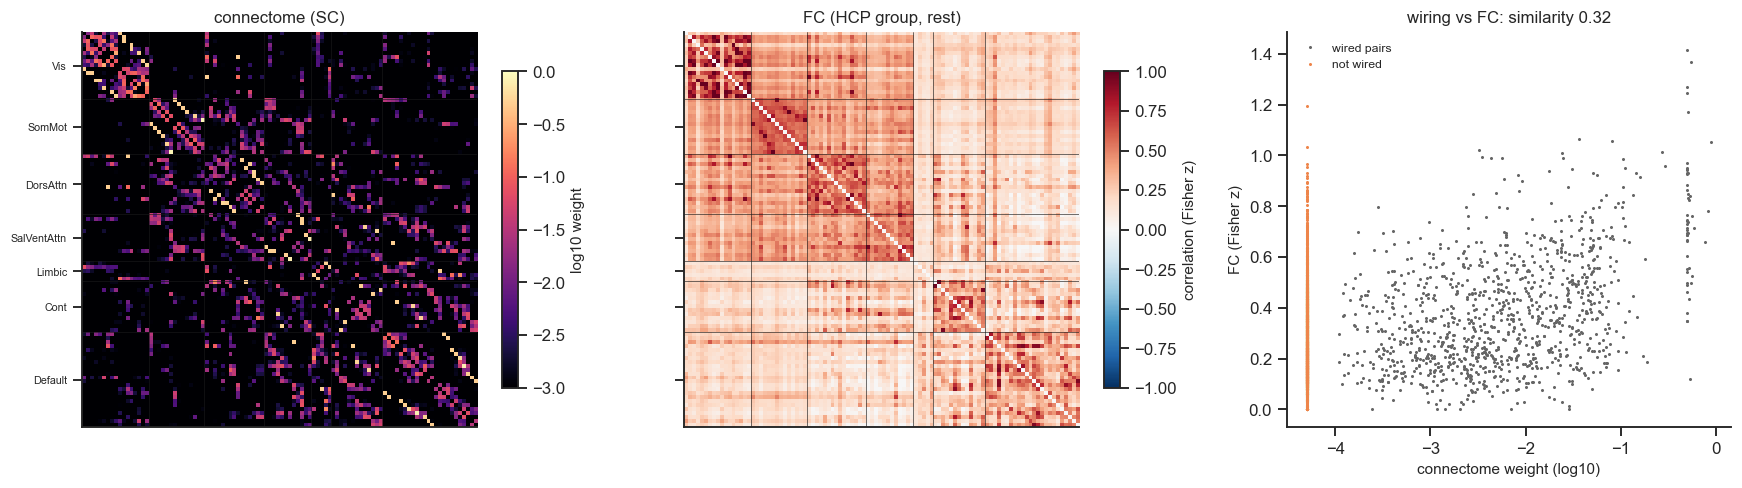

In [2]:
# @title Connectome, FC, and how much of FC the wiring alone explains
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
im = show_matrix(ax[0], np.log10(sc + 1e-3), "connectome (SC)", cmap="magma", vmin=-3, vmax=0)
plt.colorbar(im, ax=ax[0], shrink=0.8, label="log10 weight")
im = show_matrix(ax[1], fc, "FC (HCP group, rest)", labels_on=False, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="correlation (Fisher z)")
w = sc[u] > 1e-4
ax[2].plot(np.log10(sc[u][w]), fc[u][w], ".", ms=2, c="0.4", label="wired pairs")
ax[2].plot(np.full((~w).sum(), -4.3), fc[u][~w], ".", ms=2, c="C1", label="not wired")
ax[2].set(xlabel="connectome weight (log10)", ylabel="FC (Fisher z)",
          title=f"wiring vs FC: similarity {similarity(np.log1p(sc), fc):.2f}"); ax[2].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Both matrices have blocks along the diagonal (the networks), but the FC is much denser: many pairs with no direct
wire (orange) are strongly correlated. Wiring alone reaches a similarity of only about 0.3 with FC; the rest has to
come from dynamics travelling along indirect paths. **This is the number the models of NB10 and NB13 must beat.**

## 2. BOLD signals: FC is reproducible

> **Gist.** FC is computed from a few minutes of BOLD in each region. The FC of one person is noisy, but the
> average of a few people already looks like the HCP group FC.

Data: 10 adults watching a short animated film (OpenNeuro ds000228, Richardson et al. 2018), 5.6 min each,
same 100 regions. Not rest, but the network structure is largely the same.

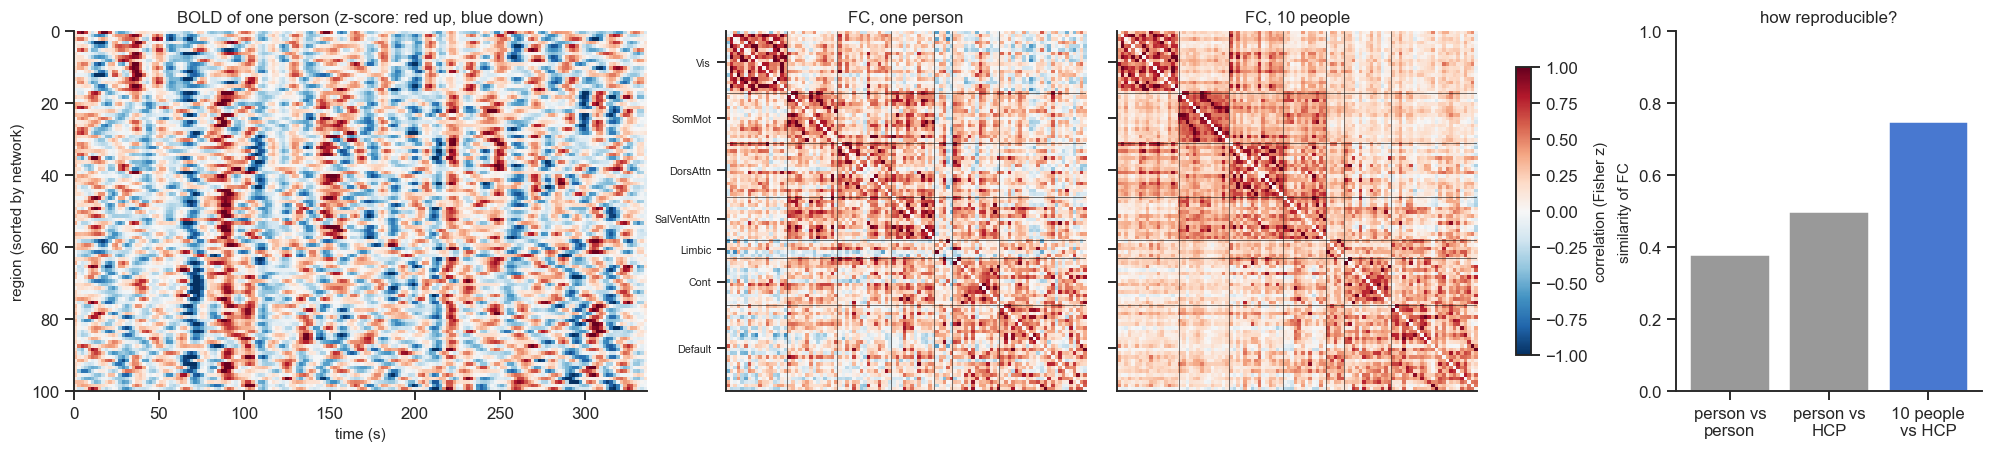

In [3]:
# @title BOLD of one person, FC of one person and of 10 people, and how similar they are
fc_sub = np.array([np.arctanh(np.clip(np.corrcoef(x.T), -0.999, 0.999)) for x in ts])   # Fisher z, as the HCP FC
for F in fc_sub: np.fill_diagonal(F, 0)
fig, ax = plt.subplots(1, 4, figsize=(18, 4), gridspec_kw=dict(width_ratios=[1.5, 1, 1, 0.8]), layout="constrained")
ax[0].imshow(ts[0][:, order].T, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5, extent=[0, ts.shape[1] * TR, 100, 0])
ax[0].set(xlabel="time (s)", ylabel="region (sorted by network)", title="BOLD of one person (z-score: red up, blue down)")
show_matrix(ax[1], fc_sub[0], "FC, one person", cmap="RdBu_r", vmin=-1, vmax=1)
im = show_matrix(ax[2], fc_sub.mean(0), "FC, 10 people", labels_on=False, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax[1:3], shrink=0.8, label="correlation (Fisher z)")
pairs = [similarity(fc_sub[i], fc_sub[j]) for i in range(10) for j in range(i)]
vals = [np.mean(pairs), np.mean([similarity(F, fc) for F in fc_sub]), similarity(fc_sub.mean(0), fc)]
ax[3].bar(["person vs\nperson", "person vs\nHCP", "10 people\nvs HCP"], vals, color=["0.6", "0.6", "C0"])
ax[3].set(ylabel="similarity of FC", ylim=(0, 1), title="how reproducible?")
plt.show()

The FC of one person matches another person, or the HCP group, only moderately; averaging 10 people raises the match
to the HCP group a lot. Much of the person-to-person difference is the noise of a short recording. This is why
models are fitted to a **group** FC, and why a model's FC must also come from long or repeated simulations.

## 3. Dynamic FC: the network changes in time

> **Gist.** Compute FC in **windows** of 1 minute that slide along the recording, then correlate the FC of every pair of
> windows (as in the slides). A static network would give similar FC in every window; the brain does not.

One number summarises it, the **variance** of the similarities between windows that do not overlap: near zero if every
minute looks alike (or if FC is pure noise), larger if patterns change and come back. The same measure is used for the
models in NB11 and NB13.

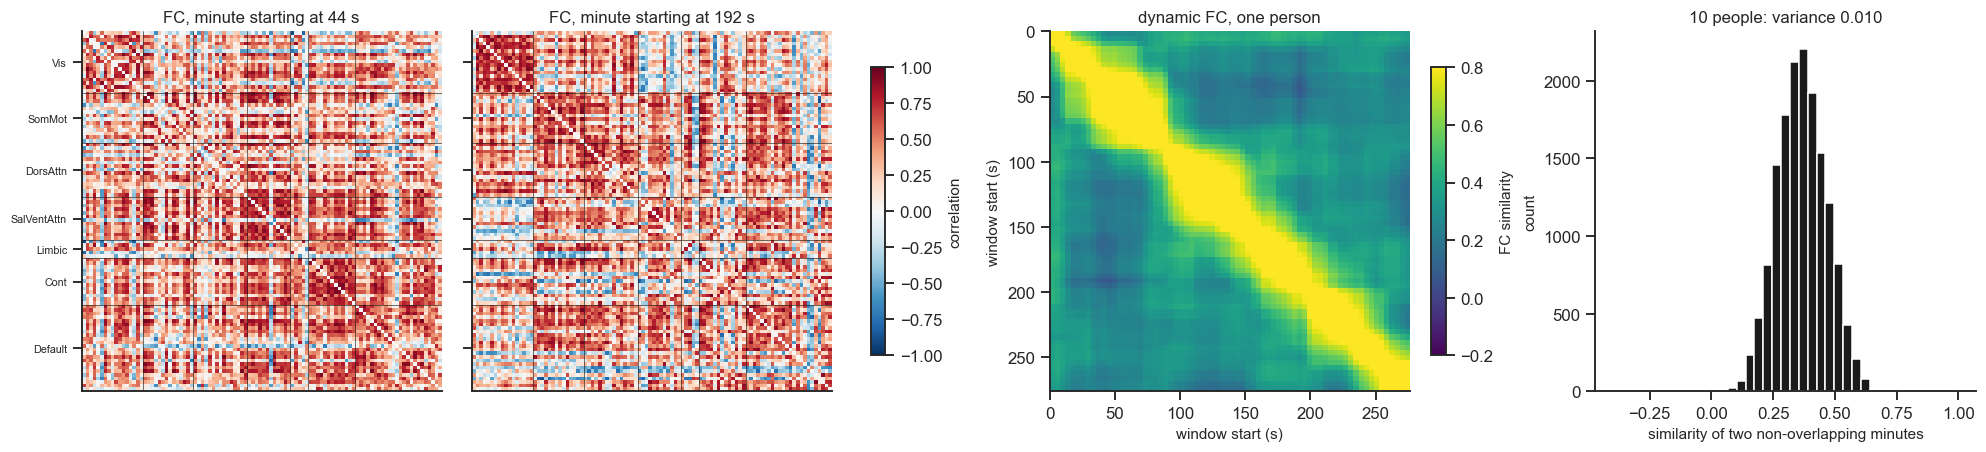

In [4]:
# @title Sliding-window FC, the dynamic FC matrix, and the spread of similarities
def window_fc(x, w=30, step=2):                     # FC in windows of w volumes (60 s), every step volumes
    return np.array([np.corrcoef(x[s:s + w].T)[u] for s in range(0, len(x) - w + 1, step)])

def dynamic_fc(x, w=30, step=2):
    F = window_fc(x, w, step); D = np.corrcoef(F)     # similarity of the FC of every pair of windows
    far = np.abs(np.subtract.outer(np.arange(len(F)), np.arange(len(F)))) * step >= w      # non-overlapping pairs
    return F, D, D[np.triu(far)]

def vec2mat(v):
    M = np.zeros((100, 100)); M[u] = v; return M + M.T

person = 0
F, D, _ = dynamic_fc(ts[person])
k1, k2 = np.unravel_index(np.argmin(D + np.eye(len(D))), D.shape)          # the two most different windows
all_vals = np.concatenate([dynamic_fc(x)[2] for x in ts])
fig, ax = plt.subplots(1, 4, figsize=(18, 4), gridspec_kw=dict(width_ratios=[1, 1, 1.15, 1]), layout="constrained")
for a_, k in zip(ax[:2], [k1, k2]):
    im = show_matrix(a_, vec2mat(F[k]), f"FC, minute starting at {k * 2 * TR:.0f} s", labels_on=a_ is ax[0], cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax[:2], shrink=0.8, label="correlation")
tmax = (len(D) - 1) * 2 * TR
im = ax[2].imshow(D, cmap="viridis", vmin=-0.2, vmax=0.8, extent=[0, tmax, tmax, 0])
ax[2].set(xlabel="window start (s)", ylabel="window start (s)", title="dynamic FC, one person"); plt.colorbar(im, ax=ax[2], shrink=0.8, label="FC similarity")
ax[3].hist(all_vals, bins=np.linspace(-0.4, 1, 40), color="k")
ax[3].set(xlabel="similarity of two non-overlapping minutes", ylabel="count", title=f"10 people: variance {all_vals.var():.3f}")
plt.show()

The two minutes on the left are the most different of this recording: the same networks, but different blocks are
strong. In the dynamic FC matrix the bright band along the diagonal is trivial (overlapping windows). Away from it,
the similarity of two separate minutes ranges from about 0.1 to 0.6: some minutes share a pattern, others do not.
This spread (right, all 10 people) is the **dynamic FC target** for the models.

<details><summary>Caveats</summary>

5.6 minutes give only a few independent windows, and part of the spread is sampling noise; longer recordings and a
null model (e.g. phase-randomised signals) are needed for firm conclusions (Hutchison et al. 2013; Lurie et al. 2020).
Here people watch a film, so part of the change follows the film itself. The window length (here 60 s) is a choice:
try others with the slider.
</details>

### Explore: person and window length

In [5]:
# @title Explore: dynamic FC for each person and window length
@interact(person=slider(0, 0, 9, 1, "person"), w=slider(30, 10, 60, 5, "window (volumes of 2 s)"))
def explore_dfc(person, w):
    F, D, vals = dynamic_fc(ts[person], w=w)
    tmax = (len(D) - 1) * 2 * TR
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].imshow(D, cmap="viridis", vmin=-0.2, vmax=0.8, extent=[0, tmax, tmax, 0])
    ax[0].set(xlabel="window start (s)", ylabel="window start (s)", title=f"person {person}, windows of {w * TR:.0f} s")
    ax[1].hist(vals, bins=np.linspace(-0.4, 1, 30), color="k")
    ax[1].set(xlabel="similarity of two non-overlapping windows", ylabel="count", title=f"variance {vals.var():.3f}")
    plt.tight_layout(); plt.show()

## 4. Take-home

* **Input:** the connectome. **Target:** the group FC. Wiring alone explains only part of FC (similarity about 0.3).
* FC is reproducible across people once averaged; single short recordings are noisy.
* FC changes from minute to minute and patterns recur: **dynamic FC** is a second, harder target.
* **Next (NB10):** your turn. Put a Hopf oscillator in every region and find the settings that reproduce this FC.

### Homework
*To do at home, after the class.*
1. **Indirect paths.** Compare the FC with the "communicability" of the connectome, `scipy.linalg.expm(sc)`, which
   counts paths of all lengths. Is it more similar to FC than the connectome itself?
2. **FC moment by moment.** Multiply the z-scored signals of every pair of regions at each time point (the "edge time
   series", Zamani Esfahlani et al. 2020). Its time average is exactly the FC. Which moments contribute most?
3. **Sleep EEG.** `np.load("../data/empirical/sleep_edf_SC4001.npz")` holds one night of EEG: `psd[stage == k]`
   are the spectra of 30-s epochs in stage `stage_names[k]`. Plot the median spectrum of each stage. How does the
   time scale of the activity change in deep sleep (N3)?

### References and data
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698–700. (HCP connectome and FC.)
* Van Essen DC et al. (2013). The WU-Minn Human Connectome Project: an overview. *NeuroImage* 80:62–79.
* Schaefer A et al. (2018). Local-global parcellation of the human cerebral cortex. *Cereb Cortex* 28:3095–3114.
* Yeo BTT et al. (2011). The organization of the human cerebral cortex estimated by intrinsic functional connectivity.
  *J Neurophysiol* 106:1125–1165.
* Richardson H, Lisandrelli G, Riobueno-Naylor A, Saxe R (2018). Development of the social brain from age three to
  twelve years. *Nat Commun* 9:1027. (OpenNeuro ds000228, CC0.)
* Hutchison RM et al. (2013). Dynamic functional connectivity: promise, issues, and interpretations. *NeuroImage*
  80:360–378.
* Lurie DJ et al. (2020). Questions and controversies in the study of time-varying functional connectivity in resting
  fMRI. *Netw Neurosci* 4:30–69.
* Zamani Esfahlani F et al. (2020). High-amplitude cofluctuations in cortical activity drive functional connectivity.
  *PNAS* 117:28393–28401.
* Kemp B et al. (2000). Analysis of a sleep-dependent neuronal feedback loop. *IEEE TBME* 47:1185–1194. (Sleep-EDF.)